# NESG: uncontrolled property decoding across all 33 ESM-2 layers

**Run this notebook first. Review its performance plots before designing controlled comparisons.**
Choose **Run all** in Colab; a CPU runtime is sufficient. No ESM extraction, SAE analysis,
restriction/matching, or reserved-test evaluation occurs here. The heterogeneous cohort
and original family distributions remain unchanged. All 33 ESM layers are used.

| Target | Meaning | Probe | Evaluation |
|---|---|---|---|
| Solubility | NESG experimental soluble recovery at high expression | L2 logistic; reuse completed fits | AUROC, AP |
| Hydrophobicity | Mean Kyte–Doolittle sequence descriptor | Ridge | R², MAE, RMSE |
| Charge proxy | (K+R−D−E)/length, not pH-dependent charge | Ridge | R², MAE, RMSE |
| Length | Natural log original sequence length | Ridge | R², MAE, RMSE |
| Aggregation propensity | AGGRESCAN Na4vSS prediction | Ridge | R², MAE, RMSE |
| APR burden | Predicted fraction of residues in aggregation-prone regions | Ridge | R², MAE, RMSE |
| Pfam membership | One presence/absence target per training-eligible family | Separate L2 logistic probes | Per-family and macro AUROC/AP |

**Persistence:** pooled activations and result checkpoints live in private HF. Drive provides code
and frozen inputs only. Complete matching runs skip fitting; partial runs resume completed layers
from HF and completed targets within the same Colab runtime. No model weights or full maps are downloaded.

**Execution status:** actual composition fits and numerical/integrity tests were run locally.
The new all-layer property results require your authenticated Colab run; there are no placeholder curves.
Existing solubility curves are reused when a compatible completed bundle is available.

## 1. Locate the project and copy only changed inputs

Change `PROJECT_ROOT` only if your Drive project is in a different location.
No credential files, full-map tensors or reserved-test files are copied.

In [1]:
from pathlib import Path
import hashlib, json, os, shutil, subprocess, sys, venv
from google.colab import drive

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/plm-property-interpretability')
source = PROJECT_ROOT / 'nesg_primary/esm_layer_probing'
work = Path('/content/nesg_property_probes')
required = [
    'common.py', 'extract.py', 'hf_storage.py', 'save_full_maps.py',
    'probe.py', 'plot_train_validation.py', 'run_layerwise_auroc.py',
    'protocol.json', 'data/extraction_manifest.tsv',
    'data/input_integrity.json', 'data/local_labels.tsv',
    'property_inputs.py', 'property_probes.py', 'property_report.py', 'run_property_probes.py',
    'data/pfam_memberships.tsv', 'data/uncontrolled/properties.tsv',
    'data/uncontrolled/family_catalog.tsv', 'data/uncontrolled/protocol.json',
    'data/uncontrolled/coverage.tsv', 'data/uncontrolled/integrity.json',
]
missing = [name for name in required if not (source / name).is_file()]
if missing:
    raise FileNotFoundError(f'Check PROJECT_ROOT and Drive sync. Missing: {missing}')
changed = 0
for name in required:
    src, dst = source / name, work / name
    dst.parent.mkdir(parents=True, exist_ok=True)
    digest = hashlib.sha256(src.read_bytes()).digest()
    if not dst.is_file() or hashlib.sha256(dst.read_bytes()).digest() != digest:
        shutil.copyfile(src, dst)
        changed += 1
    assert hashlib.sha256(dst.read_bytes()).digest() == digest
os.chdir(work)
print(f'Updated {changed} code/input files; unchanged files reused.')

Mounted at /content/drive
Updated 21 code/input files; unchanged files reused.


## 2. Prepare or reuse the CPU probing environment

Reuse the extraction interpreter if it still exists. Otherwise create a small
separate environment inheriting Colab's numerical stack. Only missing probing
packages are installed as prebuilt wheels; there is no CUDA preflight, ESM
download or PyTorch installation. Package versions are recorded in the results.

In [2]:
import shlex
from IPython.utils.process import system

os.environ.update(USE_TORCH='1', USE_TF='0', USE_FLAX='0', PYTHONNOUSERSITE='1', MPLBACKEND='Agg')
EXTRACTION_PYTHON = Path('/content/nesg_esm_env/bin/python')
if not EXTRACTION_PYTHON.is_file():
    environment = Path('/content/nesg_probe_env')
    EXTRACTION_PYTHON = environment / 'bin/python'
    if not EXTRACTION_PYTHON.is_file():
        venv.EnvBuilder(system_site_packages=True, with_pip=False).create(environment)

def run_stage1(*arguments):
    status = system(shlex.join([str(EXTRACTION_PYTHON), '-u', *map(str, arguments)]))
    if status != 0:
        raise RuntimeError(f'Command stopped (exit {status}). See the output above.')

run_stage1('run_layerwise_auroc.py', '--setup-only')

Installing only probing/plotting packages: ['huggingface-hub==0.36.0', 'scipy==1.15.3', 'scikit-learn==1.7.2', 'joblib==1.5.2', 'threadpoolctl==3.6.0', 'matplotlib==3.10.7']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 7.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 62.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 79.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 72.7 MB/s  0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Not uninstalling threadpoolctl at /usr/local/lib/python3.13/dist-packages, outside environment /content/nesg_probe_env
    Can't uninstall 'threadpoolctl'. No files were found to uninstall.
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Not uninstalling scipy at /usr/local/lib/python3.13/dist-packages, outside environment /content/nesg_probe_env
    Can't uninstall 'scipy'. No files were found 

## 3. Authenticate securely

Enable notebook access to `HF_TOKEN_PLM` in Colab Secrets. The configured dataset must already
exist and be private. No repository is created. The runner first checks saved results using small
metadata files; it downloads pooled arrays only if an unfinished layer needs fitting. Completed
runs reopen without downloading activations or refitting. Full residue maps are never downloaded.

In [4]:
from google.colab import userdata
try:
    secret = userdata.get('HF_TOKEN_PLM')
except Exception:
    raise RuntimeError('Enable notebook access to HF_TOKEN_PLM in Colab Secrets.') from None
if not secret:
    raise RuntimeError('HF_TOKEN_PLM is missing from Colab Secrets.')
os.environ['HF_TOKEN_PLM'] = secret
del secret
DESTINATION_REPO = 'PLM-Interp/nesg-esm2-layerwise'
OUTPUT = Path('/content/nesg_esm_stage1_scratch/activations')
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Configured private HF destination. Cached results will be checked before downloading activations.')

Configured private HF destination. Cached results will be checked before downloading activations.


## 4. Verify annotations and target eligibility

The frozen manifests contain **2,361 training and 691 validation proteins**. The three sequences
containing X remain in the cohort. For hydropathy, charge proxy and AGGRESCAN targets, their undefined
values are omitted only from that target's fits/evaluation: **2,359 training and 690 validation**.
Zero APR burden is a valid prediction and is retained.

Family targets require ≥5 positive and ≥5 negative **training homology groups**, with both membership
classes in every held-out fold and fitting complement. This yields **21 families**; it selects target
tasks, not proteins. Every protein remains an example for every family task. A protein can be positive
for several Pfam families. This is family-membership prediction, not within-family solubility evaluation.
Absence of a GA-passing hit is an annotation-defined negative, not proof of biological absence.
Of these 21 training-eligible targets, **16 have positives in validation**; the other five remain
in the output with undefined discrimination. Some of the 16 have only one validation positive.

In [5]:
run_stage1('-c', r'''
from property_inputs import load_inputs
from pathlib import Path
import pandas as pd
d,p,m,c=load_inputs()
assert d.split.value_counts().to_dict()=={'train':2361,'validation':691}
assert set(d.loc[d.split=='train','audit_cluster']).isdisjoint(d.loc[d.split=='validation','audit_cluster'])
print(pd.read_csv('data/uncontrolled/coverage.tsv',sep='\t').to_string(index=False))
print('\nFamily targets selected using training only:')
print(c.loc[c.eligible,['pfam','name','train_positive','train_negative','train_positive_groups']].to_string(index=False))
print('\nFrozen sequence hashes, annotation hashes, splits and homology separation passed.')
''')

     split             target  total  observed  missing
     train     hydrophobicity   2361      2359        2
     train       charge_proxy   2361      2359        2
     train         log_length   2361      2361        0
     train aggregation_Na4vSS   2361      2359        2
     train       apr_fraction   2361      2359        2
validation     hydrophobicity    691       690        1
validation       charge_proxy    691       690        1
validation         log_length    691       691        0
validation aggregation_Na4vSS    691       690        1
validation       apr_fraction    691       690        1

Family targets selected using training only:
   pfam            name  train_positive  train_negative  train_positive_groups
PF00004             AAA              17            2344                     11
PF00535 Glycos_transf_2              48            2313                     26
PF00890   FAD_binding_2              40            2321                     22
PF01209 Ubie_methyltra

## 5. Fit or resume uncontrolled property probes

Standardization is fitted separately inside each training fold. Binary probes select C from
`[0.0001, 0.001, 0.01, 0.1, 1, 10]` by mean fold AUROC. Continuous probes select ridge alpha from
`[0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]` by minimum mean fold MSE. Targets remain in
their original units (length is explicitly log-transformed). Each selected model is refitted on all
observed training examples and evaluated on the fixed validation examples for that target.

There is no class balancing or validation-driven tuning. Each target has a composition + log-length
baseline and a training-mean/prevalence constant reference. The same training folds tune and report
CV performance; these are tuning estimates, **not nested-CV generalization estimates**.

Completed solubility fits are matched by input/protocol/code/activation hashes and reused. If none
match, the runner announces that it will fit them under the unchanged protocol. Every completed
layer is uploaded atomically with hashes to the existing private HF dataset. No observed per-protein
targets or sequences are included in uploaded prediction tables. IDs/hashes permit local annotation joins.

This fits many more models than the solubility-only notebook. Progress prints each completed target;
if interrupted, rerun this cell. A deleted runtime loses at most the unfinished layer's fits.

In [6]:
run_stage1('run_property_probes.py', '--activations', OUTPUT,
           '--repo', DESTINATION_REPO, '--threads', '2')
latest = json.loads(Path('/content/nesg_uncontrolled_probes/latest.json').read_text())
results = Path(latest['results'])
from IPython.display import Image, Markdown, display
print('Verified results:', results)

completed.json: 8.95kB [00:00, 27.7MB/s]
completed.json: 1.50kB [00:00, 5.86MB/s]
esm_stage1/layerwise_probing_v1/19424161(…): 100%|█| 15.4M/15.4M [00:00<00:00, 1
Reusing 33 completed solubility probes and composition baseline; no refitting.
Fitting composition baseline: 27 targets
  Completed hydrophobicity
  Completed charge_proxy
  Completed log_length
  Completed aggregation_Na4vSS
  Completed apr_fraction
  Completed PF00004
  Completed PF00535
  Completed PF00890
  Completed PF01209
  Completed PF01266
  Completed PF01385
  Completed PF01494
  Completed PF01844
  Completed PF04055
  Completed PF04909
  Completed PF05175
  Completed PF07282
  Completed PF07728
  Completed PF08241
  Completed PF08242
  Completed PF12831
  Completed PF13450
  Completed PF13489
  Completed PF13641
  Completed PF13649
  Completed PF13847
Processing Files (0 / 0)      : |                  |  0.00B /  0.00B            
New Data Upload               : |                  |  0.00B /  0.00B            

   

## 6. Experimental soluble-recovery decoding

The train curve is mean held-out-fold AUROC (±1 SD); validation has a pointwise 95% homology-group
bootstrap CI. The two bands have different meanings. Existing validated fits are reused, so this
panel connects the new property analysis to the previous solubility result.

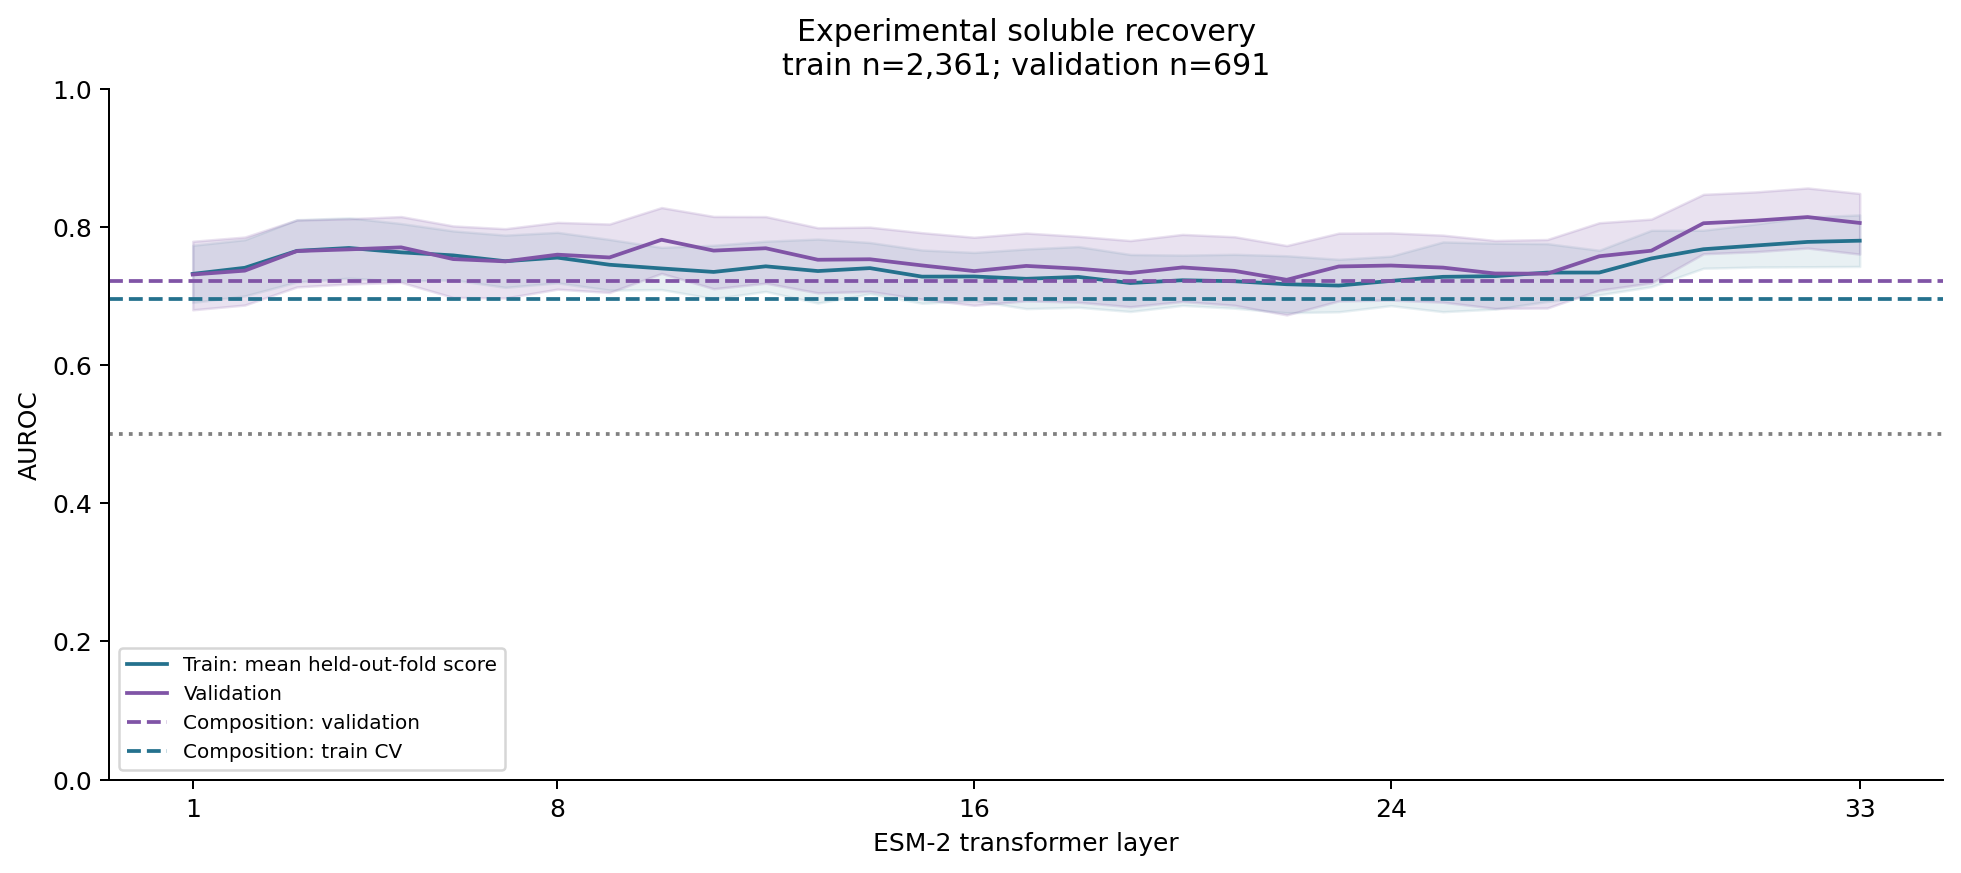

In [7]:
display(Image(filename=str(results / 'figures/solubility_auroc.png')))

**Interpretation:** above-chance discrimination shows linearly accessible association with
NESG soluble recovery. It does not tell us whether the model uses family, composition, aggregation,
or other features, and does not establish a causal mechanism.

## 7. Continuous biological descriptors and predicted aggregation

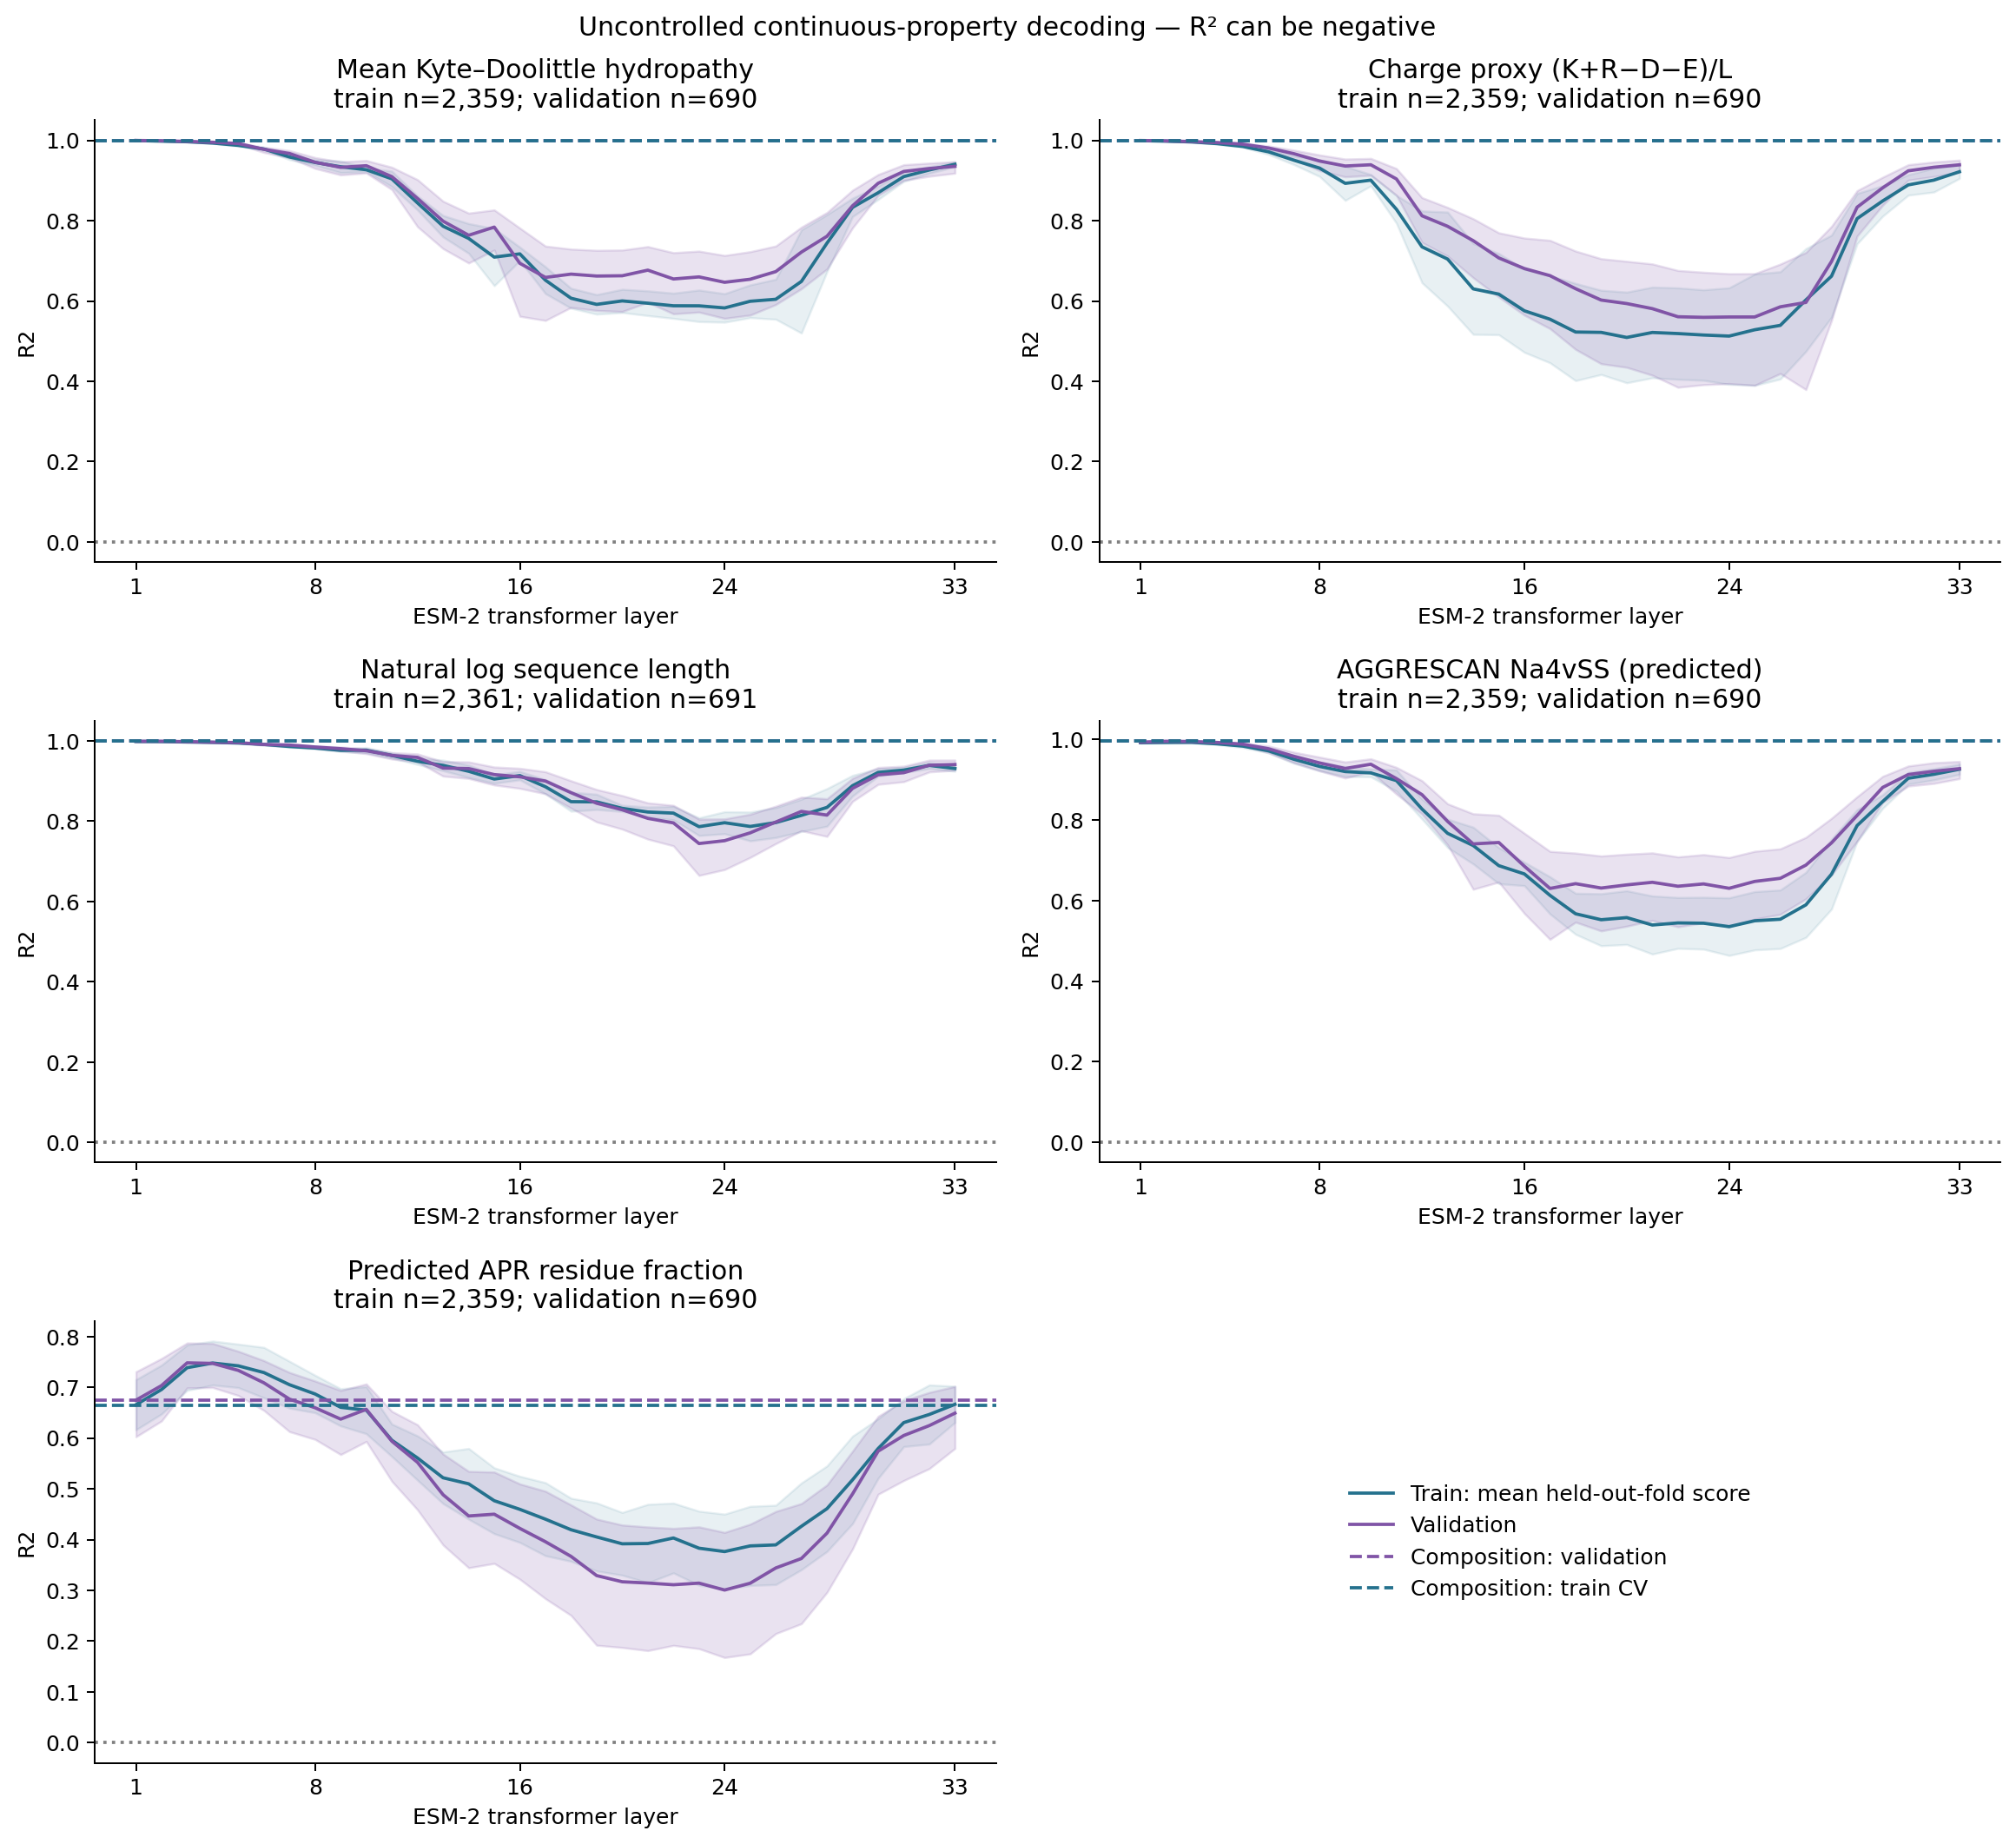

In [8]:
display(Image(filename=str(results / 'figures/continuous_r2.png')))

**Interpretation:** R² = 1 indicates perfect prediction; R² = 0 matches the validation-mean
reference, and negative values are possible. The separate training-mean constant baseline is saved
in the tables and need not have R² exactly zero on validation. Hydrophobicity and charge proxy are
linear functions of composition, while log length is directly supplied to the baseline. Near-perfect
composition performance is therefore expected. ESM performance measures retention/linear accessibility
of these descriptors, not additional experimental knowledge. AGGRESCAN outputs are predictions.

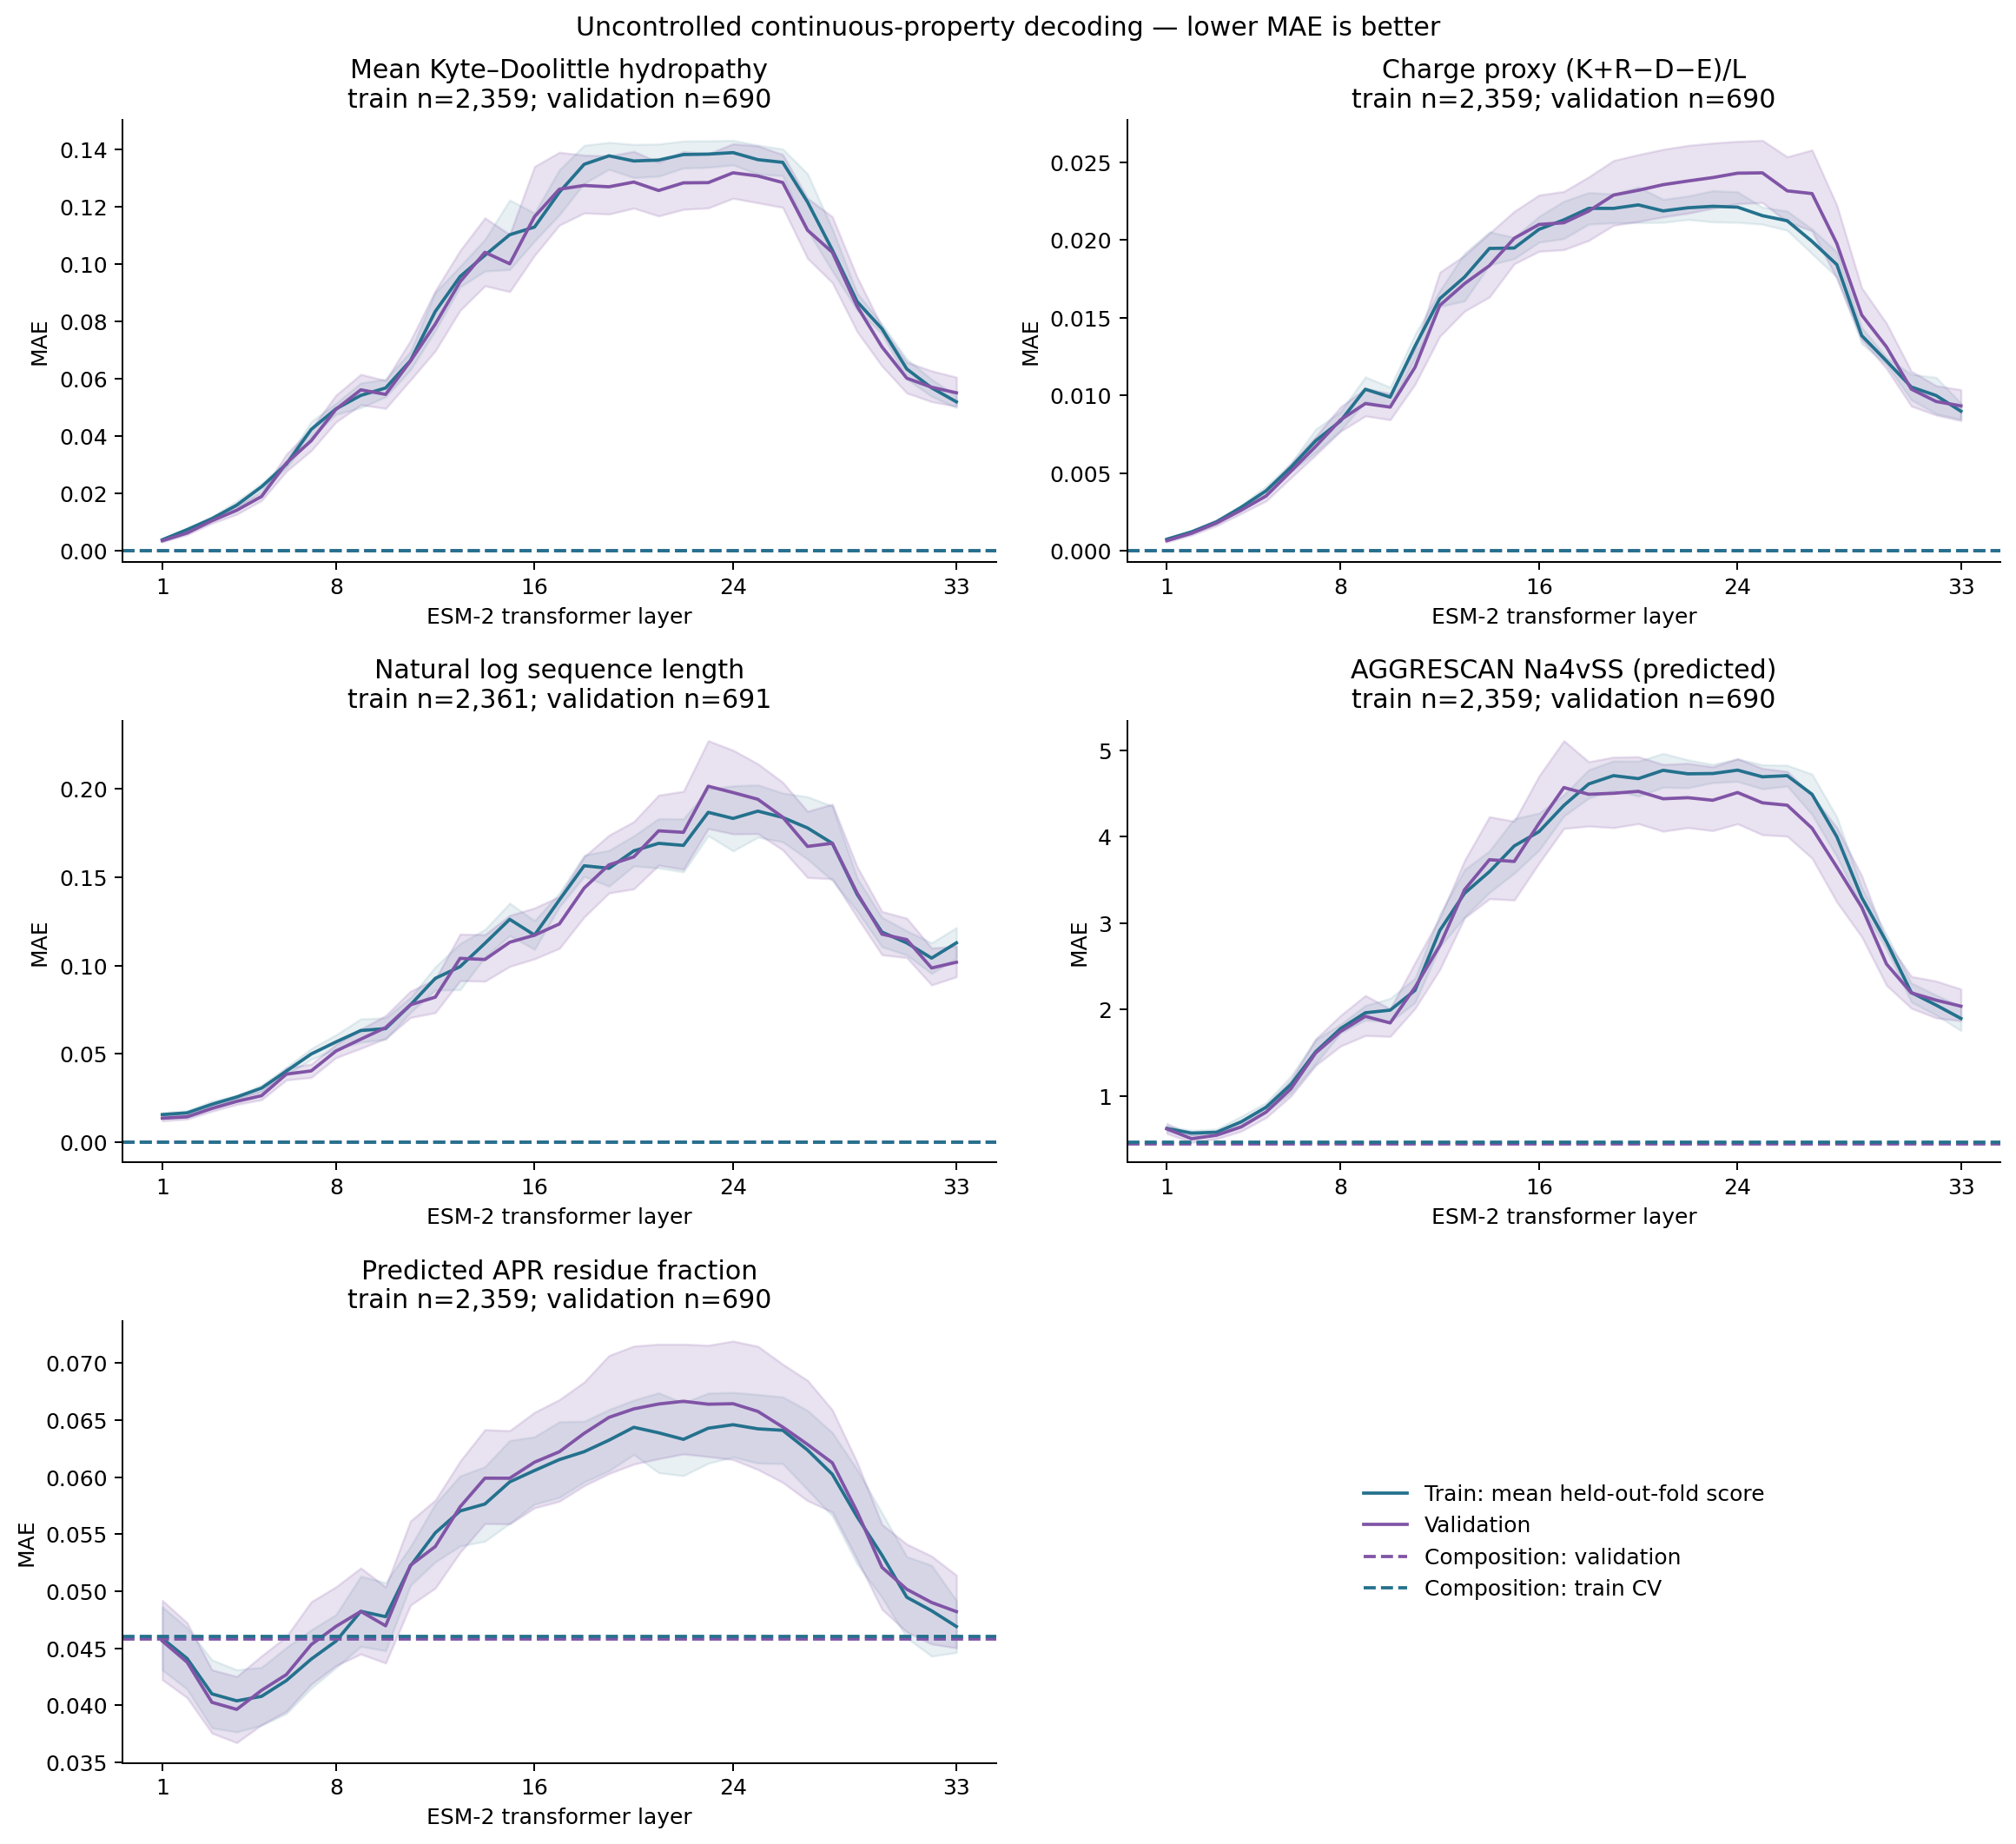

In [9]:
display(Image(filename=str(results / 'figures/continuous_mae.png')))

**Interpretation:** MAE is in each target's units and lower is better. Compare layers within
a target; do not rank different properties by their raw MAEs or compare R² numerically with AUROC.
Only paired differences measured on the same target population support ESM-versus-composition comparisons.

## 8. Pfam family-membership decoding

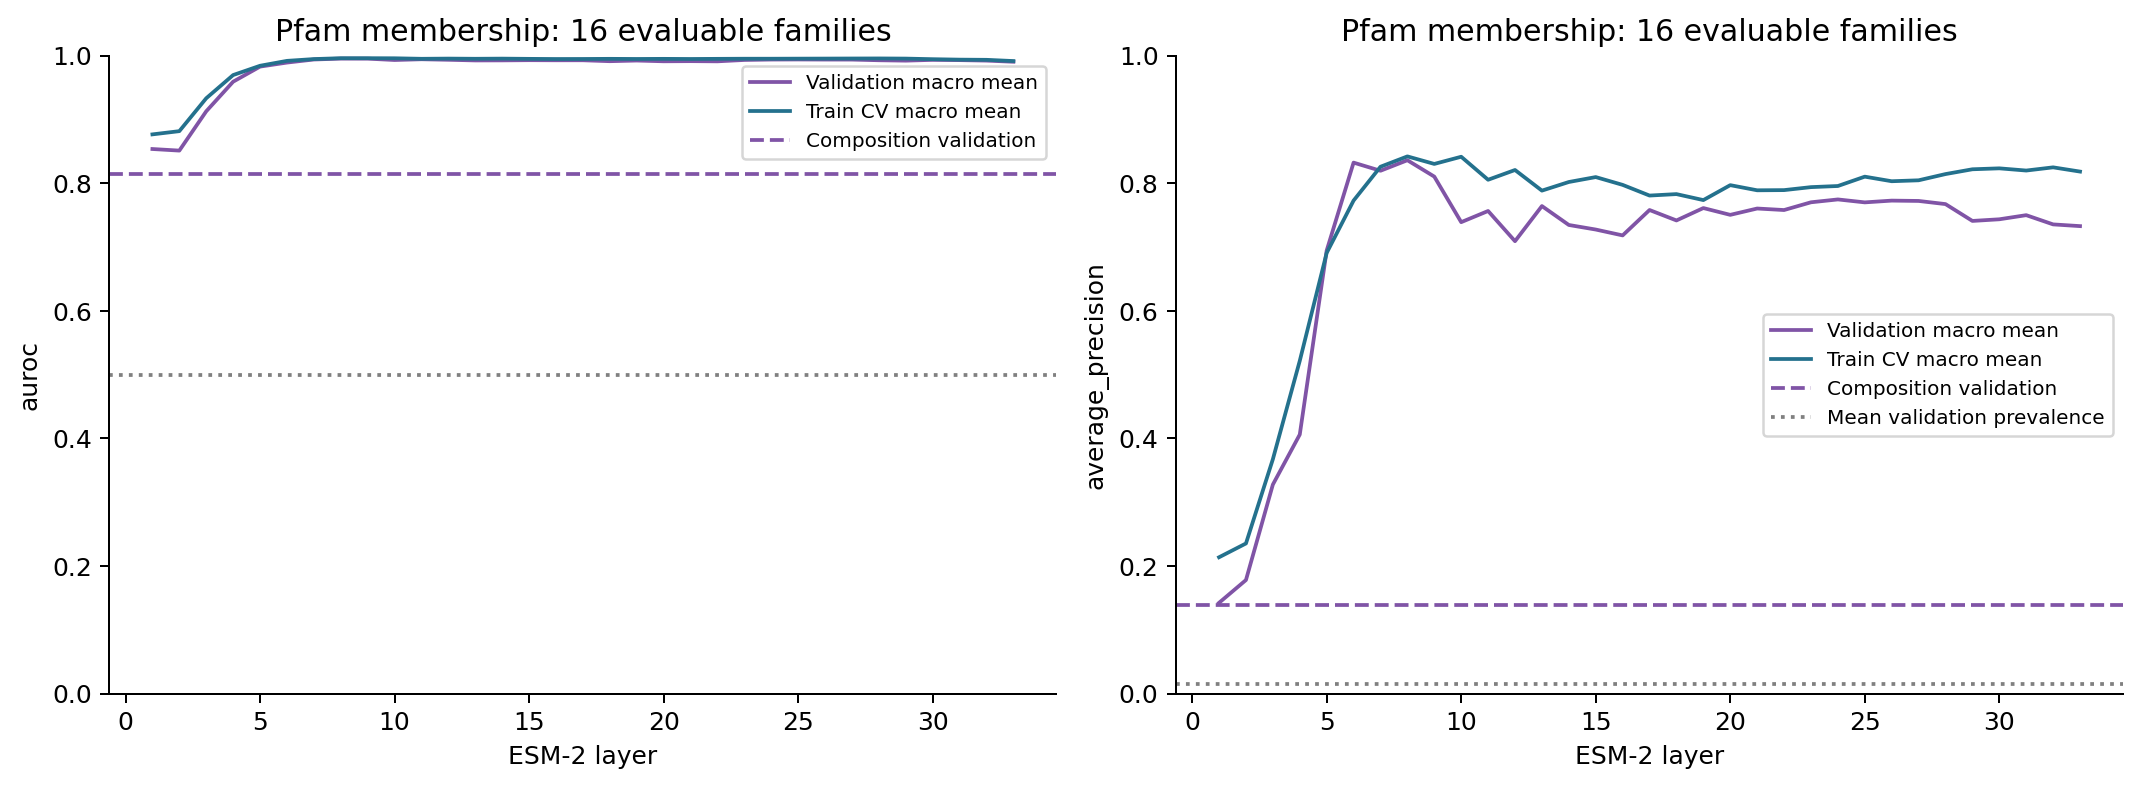

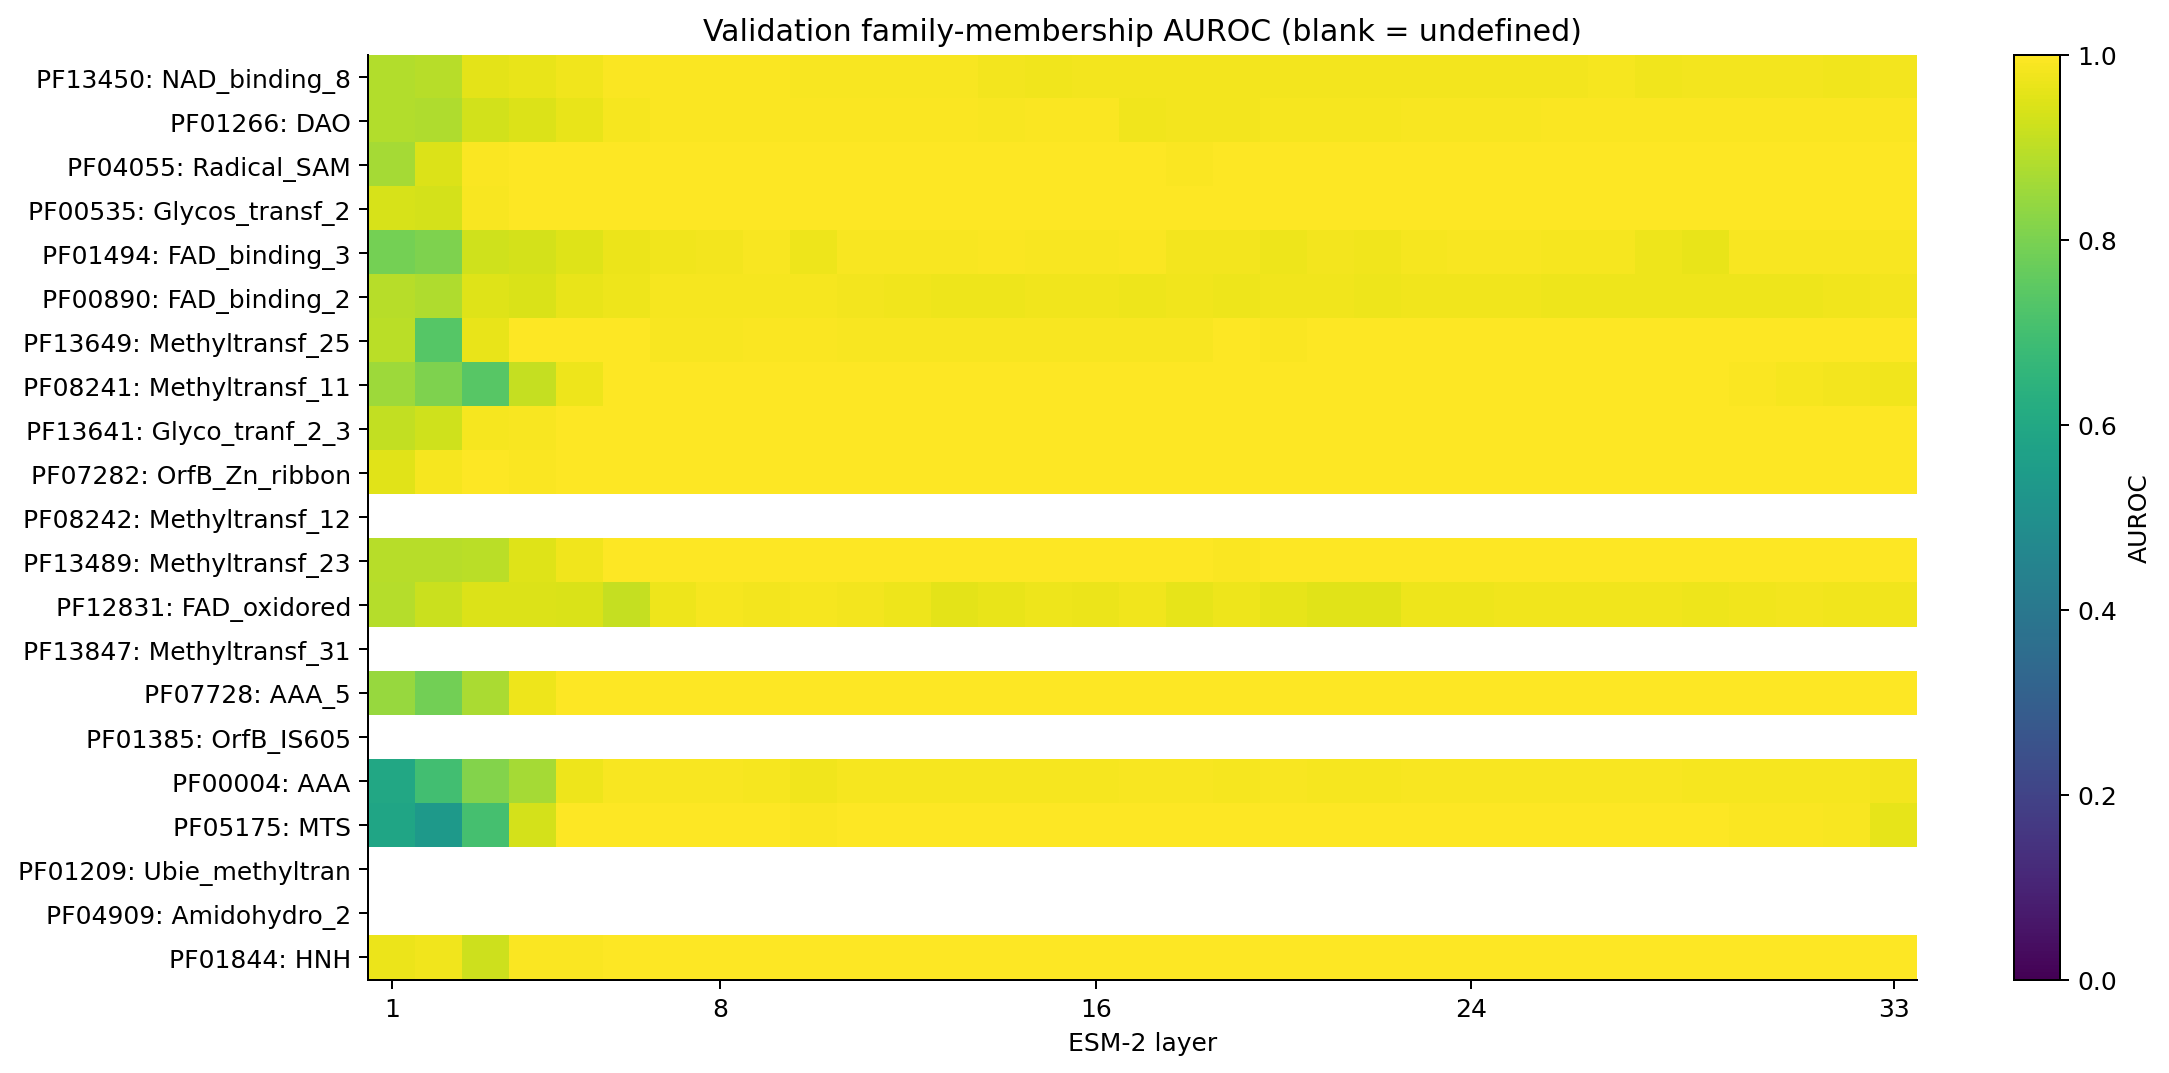

In [10]:
display(Image(filename=str(results / 'figures/family_macro.png')))
display(Image(filename=str(results / 'figures/family_heatmap.png')))

**Interpretation:** each family is a separate membership target, with all heterogeneous
proteins retained. Macro averages give each evaluable family equal weight. AP must be read against
family prevalence. A family without both membership classes in validation has undefined discrimination
and is reported explicitly. The same evaluable family set is used across layers and valid bootstrap
draws. Sparse positive support can make intervals wide or reduce valid bootstrap draws.
Macro intervals are omitted if fewer than 90% of draws support every included family; exact valid
draw counts are saved in `family_macro.tsv`. A missing band is not evidence of zero uncertainty.

These are annotation-presence probes. All GA-passing memberships, including competing overlapping
assignments, are retained. This notebook does not resolve architecture ambiguity or establish
within-family solubility contrasts. Predicting a family's membership *inside a subset where every
protein has that family* would be a constant-target task and is not a useful controlled probe.

## 9. Exact results and the decision before controlled analyses

In [11]:
import csv
def show_tsv(path, columns):
    with path.open() as handle:
        rows = list(csv.DictReader(handle, delimiter='\t'))
    text = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---']*len(columns)) + ' |']
    for row in rows:
        text.append('| ' + ' | '.join(str(row.get(c,'')) for c in columns) + ' |')
    display(Markdown('\n'.join(text)))
show_tsv(results / 'family_support.tsv', ['pfam','name','train_positive','validation_positive','validation_negative','validation_estimable'])
from IPython.display import HTML
import html, math
with (results / 'metrics.tsv').open() as handle:
    all_metrics = list(csv.DictReader(handle, delimiter='\t'))
for target in dict.fromkeys(row['target'] for row in all_metrics):
    rows = [r for r in all_metrics if r['target'] == target and r['metric'] in ('r2','auroc')]
    def number(value):
        try:
            x = float(value)
            return f'{x:.4f}' if math.isfinite(x) else 'undefined'
        except (ValueError, TypeError):
            return 'undefined'
    body = '<tr><th>Layer (0 = composition)</th><th>Metric</th><th>Train CV</th><th>Validation</th><th>95% CI</th><th>Valid bootstrap draws</th></tr>'
    for row in rows:
        cells = [row['layer'], row['metric'], number(row['cv_mean']), number(row['validation']),
                 number(row['low']) + ' – ' + number(row['high']), row['bootstrap_valid']]
        body += '<tr>' + ''.join('<td>' + html.escape(x) + '</td>' for x in cells) + '</tr>'
    display(HTML('<details><summary>' + html.escape(target) + ': exact results for all layers</summary><table>' + body + '</table></details>'))
display(Markdown((results / 'UNCONTROLLED_RESULTS.md').read_text()))
url = f"https://huggingface.co/datasets/{latest['repository']}/tree/main/{latest['hf_prefix']}"
display(Markdown(f'[Private HF checkpoints and figures]({url}). Summary tables/plots are in `summary/results.zip`; each `layer_XX/results.zip` contains fitted parameters, CV results and predictions. Layer 00 is composition.'))

| pfam | name | train_positive | validation_positive | validation_negative | validation_estimable |
| --- | --- | --- | --- | --- | --- |
| PF00004 | AAA | 17 | 11.0 | 680.0 | True |
| PF00535 | Glycos_transf_2 | 48 | 17.0 | 674.0 | True |
| PF00890 | FAD_binding_2 | 40 | 18.0 | 673.0 | True |
| PF01209 | Ubie_methyltran | 13 | 0.0 | 691.0 | False |
| PF01266 | DAO | 62 | 21.0 | 670.0 | True |
| PF01385 | OrfB_IS605 | 18 | 0.0 | 691.0 | False |
| PF01494 | FAD_binding_3 | 45 | 20.0 | 671.0 | True |
| PF01844 | HNH | 8 | 4.0 | 687.0 | True |
| PF04055 | Radical_SAM | 52 | 3.0 | 688.0 | True |
| PF04909 | Amidohydro_2 | 11 | 0.0 | 691.0 | False |
| PF05175 | MTS | 14 | 1.0 | 690.0 | True |
| PF07282 | OrfB_Zn_ribbon | 28 | 1.0 | 690.0 | True |
| PF07728 | AAA_5 | 19 | 13.0 | 678.0 | True |
| PF08241 | Methyltransf_11 | 34 | 8.0 | 683.0 | True |
| PF08242 | Methyltransf_12 | 26 | 0.0 | 691.0 | False |
| PF12831 | FAD_oxidored | 21 | 12.0 | 679.0 | True |
| PF13450 | NAD_binding_8 | 69 | 25.0 | 666.0 | True |
| PF13489 | Methyltransf_23 | 26 | 7.0 | 684.0 | True |
| PF13641 | Glyco_tranf_2_3 | 30 | 10.0 | 681.0 | True |
| PF13649 | Methyltransf_25 | 35 | 1.0 | 690.0 | True |
| PF13847 | Methyltransf_31 | 21 | 0.0 | 691.0 | False |

Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,auroc,0.6961,0.7216,0.6669 – 0.7739,2000
1,auroc,0.7323,0.7314,0.6803 – 0.7795,2000
2,auroc,0.7411,0.7370,0.6872 – 0.7856,2000
3,auroc,0.7656,0.7653,0.7134 – 0.8104,2000
4,auroc,0.7698,0.7678,0.7177 – 0.8121,2000
5,auroc,0.7635,0.7707,0.7200 – 0.8153,2000
6,auroc,0.7591,0.7537,0.6981 – 0.8017,2000
7,auroc,0.7506,0.7504,0.6974 – 0.7977,2000
8,auroc,0.7558,0.7601,0.7102 – 0.8069,2000
9,auroc,0.7455,0.7561,0.7053 – 0.8045,2000


Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,r2,1.0000,1.0000,1.0000 – 1.0000,2000
1,r2,0.9995,0.9996,0.9995 – 0.9997,2000
2,r2,0.9980,0.9989,0.9985 – 0.9992,2000
3,r2,0.9965,0.9973,0.9964 – 0.9979,2000
4,r2,0.9932,0.9952,0.9937 – 0.9963,2000
5,r2,0.9874,0.9921,0.9900 – 0.9936,2000
6,r2,0.9783,0.9777,0.9698 – 0.9831,2000
7,r2,0.9585,0.9671,0.9566 – 0.9744,2000
8,r2,0.9448,0.9454,0.9300 – 0.9572,2000
9,r2,0.9341,0.9327,0.9138 – 0.9466,2000


Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,r2,1.0000,1.0000,1.0000 – 1.0000,2000
1,r2,0.9991,0.9996,0.9994 – 0.9997,2000
2,r2,0.9980,0.9986,0.9980 – 0.9990,2000
3,r2,0.9961,0.9969,0.9957 – 0.9978,2000
4,r2,0.9918,0.9945,0.9924 – 0.9959,2000
5,r2,0.9847,0.9904,0.9867 – 0.9928,2000
6,r2,0.9714,0.9810,0.9731 – 0.9860,2000
7,r2,0.9504,0.9666,0.9523 – 0.9755,2000
8,r2,0.9308,0.9484,0.9245 – 0.9636,2000
9,r2,0.8929,0.9360,0.9092 – 0.9534,2000


Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,r2,1.0000,1.0000,1.0000 – 1.0000,2000
1,r2,0.9981,0.9985,0.9980 – 0.9989,2000
2,r2,0.9978,0.9986,0.9983 – 0.9988,2000
3,r2,0.9967,0.9975,0.9969 – 0.9979,2000
4,r2,0.9959,0.9963,0.9955 – 0.9970,2000
5,r2,0.9943,0.9953,0.9941 – 0.9962,2000
6,r2,0.9907,0.9906,0.9885 – 0.9924,2000
7,r2,0.9855,0.9892,0.9863 – 0.9915,2000
8,r2,0.9819,0.9843,0.9809 – 0.9868,2000
9,r2,0.9761,0.9802,0.9746 – 0.9843,2000


Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,r2,0.9953,0.9964,0.9953 – 0.9972,2000
1,r2,0.9914,0.9928,0.9908 – 0.9940,2000
2,r2,0.9920,0.9950,0.9935 – 0.9961,2000
3,r2,0.9923,0.9944,0.9925 – 0.9956,2000
4,r2,0.9886,0.9921,0.9895 – 0.9940,2000
5,r2,0.9830,0.9878,0.9845 – 0.9903,2000
6,r2,0.9714,0.9765,0.9666 – 0.9831,2000
7,r2,0.9502,0.9576,0.9419 – 0.9678,2000
8,r2,0.9325,0.9412,0.9215 – 0.9557,2000
9,r2,0.9198,0.9275,0.9037 – 0.9436,2000


... (20 outputs left out)

Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,auroc,0.7595,0.9319,0.9063 – 0.9554,1247
1,auroc,0.8576,0.8957,0.8626 – 0.9273,1247
2,auroc,0.8725,0.7348,0.6782 – 0.7843,1247
3,auroc,0.9288,0.9667,0.9507 – 0.9796,1247
4,auroc,0.9941,0.9986,0.9954 – 1.0000,1247
5,auroc,0.9994,1.0000,1.0000 – 1.0000,1247
6,auroc,0.9996,1.0000,1.0000 – 1.0000,1247
7,auroc,0.9996,0.9913,0.9732 – 1.0000,1247
8,auroc,0.9999,0.9913,0.9727 – 1.0000,1247
9,auroc,0.9999,0.9928,0.9747 – 1.0000,1247


Layer (0 = composition),Metric,Train CV,Validation,95% CI,Valid bootstrap draws
0,auroc,0.7442,undefined,undefined – undefined,0
1,auroc,0.8785,undefined,undefined – undefined,0
2,auroc,0.8683,undefined,undefined – undefined,0
3,auroc,0.9086,undefined,undefined – undefined,0
4,auroc,0.9563,undefined,undefined – undefined,0
5,auroc,0.9964,undefined,undefined – undefined,0
6,auroc,0.9970,undefined,undefined – undefined,0
7,auroc,0.9965,undefined,undefined – undefined,0
8,auroc,0.9959,undefined,undefined – undefined,0
9,auroc,0.9958,undefined,undefined – undefined,0


# Uncontrolled property-probe results

All 33 layers evaluated on the unchanged development cohort: 2,361 training and 691 validation proteins. No reserved-test records were accessed. Continuous targets with undefined X-residue descriptors use 2,359/690 proteins; length and binary targets use all 2,361/691. Missing targets are never zero-filled.

There are 21 training-eligible Pfam membership targets; 16 have both membership classes in validation. Family qualification uses training only. All proteins remain eligible examples for each membership probe. Pfam presence is annotation-defined; a negative can mean no detected hit, not verified biological absence. Overlapping assignments are retained.

R² and MAE describe continuous-target decoding; AUROC/AP describe binary targets. These scales are not comparable. Hydrophobicity and charge are linear functions of composition; log length is a baseline input. Their composition baseline should be near-perfect and is a diagnostic reference, not an independent biological discovery. AGGRESCAN targets are predictions, not aggregation measurements.

Training bands show ±1 fold SD. Validation bands are pointwise 95% homology-group bootstrap intervals conditional on fitted models. The same training folds select regularization; CV scores are tuning estimates, not nested-CV estimates. Intervals omit model-fitting and layer/target selection uncertainty. Family macro intervals retain the same families in every valid resample; valid draw counts are reported. A macro interval is suppressed if fewer than 90% of resamples support every included family, rather than presenting a heavily conditioned interval. Sparse individual-family intervals also need caution.

`metrics.tsv` contains every target/layer result; `paired_vs_composition.tsv` uses the same group resamples for paired differences (ESM minus composition; negative MAE/RMSE differences favor ESM). `family_support.tsv` reports exact denominators. `constant_baselines.tsv` gives training-mean/prevalence references. Each layer directory stores coefficients, scalers, tuning scores and ID/hash-aligned predictions. Observed per-protein targets remain in local inputs.

Review these unrestricted results before specifying controlled comparisons. Strong decoding does not establish direct encoding or a causal computation; weak decoding does not establish absence of information. No restriction, matching, family-controlled evaluation, SAE feature analysis or intervention was performed.


[Private HF checkpoints and figures](https://huggingface.co/datasets/PLM-Interp/nesg-esm2-layerwise/tree/main/esm_stage1/uncontrolled_property_probing_v1/0cfeb002caa19af126f22df1a3e2d6e654e2ad9273f8a71dd266db3509a99cb4). Summary tables/plots are in `summary/results.zip`; each `layer_XX/results.zip` contains fitted parameters, CV results and predictions. Layer 00 is composition.

**Stop here and inspect the results.** Next we can prespecify controlled comparisons using
the same globally trained solubility/property probes: for example within supported families or within
training-defined hydrophobicity ranges, provided target variation and independent validation support
remain. Restricted-population AUROC changes alone are not causal estimates of confounding and can
reflect changed difficulty, target range and sample size. Family membership is constant inside one
family; it should not be evaluated as a discrimination task there. Do not choose restrictions because
they yield the largest observed AUROC drop. No such analysis is run by this notebook.